# Matplotlib

**Subject:** Introduction to Problem Solving and Reasoning (IPSR)  
**Unit 1 (Python Basics), Topic 17**  
**How to use this notebook:** read each section, run every code cell (Shift + Enter), then change the examples and run them again. Try each exercise before you open its solution.

## 1. Learning goals

After this notebook you can:

* draw a line plot, scatter plot, bar chart and histogram
* add a title, axis labels, a legend and a grid
* use the object-oriented style `fig, ax = plt.subplots()`
* put several plots in one figure
* save a figure to a file
* avoid the traps: `plt.show()` in scripts, different-length data, state leaking between plots, log scale with zeros, category order

## 2. Setup

**Matplotlib** is the standard Python library for drawing graphs. We use its `pyplot` module, usually imported as `plt`.

The line `%matplotlib inline` tells Jupyter to show figures inside the notebook, right under the cell.

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
print(matplotlib.__version__)

3.11.2


## 3. Your first line plot

`plt.plot(x, y)` joins the points `(x, y)` with a line. Every graph should have a **title**, **axis labels** (with units) and, when there are several lines, a **legend**.

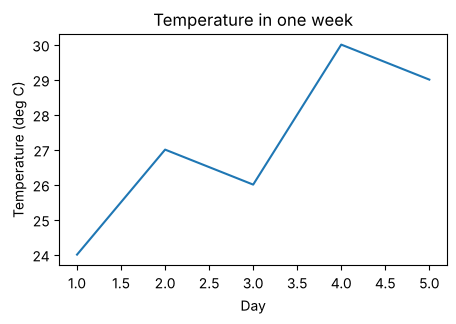

In [2]:
days = [1, 2, 3, 4, 5]
temp = [24, 27, 26, 30, 29]

plt.figure(figsize=(5, 3))
plt.plot(days, temp)
plt.title("Temperature in one week")
plt.xlabel("Day")
plt.ylabel("Temperature (deg C)")
plt.show()

Add markers, a colour, a line style and a grid to make the plot easier to read.

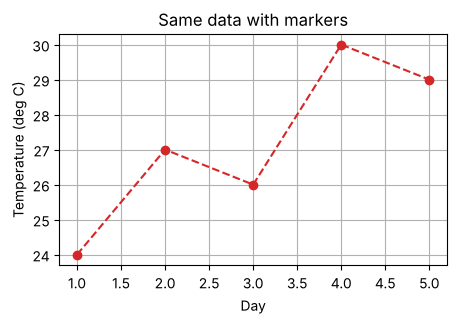

In [3]:
plt.figure(figsize=(5, 3))
plt.plot(days, temp, marker="o", color="tab:red", linestyle="--")
plt.title("Same data with markers")
plt.xlabel("Day")
plt.ylabel("Temperature (deg C)")
plt.grid(True)
plt.show()

### Several lines and a legend
Give each line a `label`, then call `legend()`.

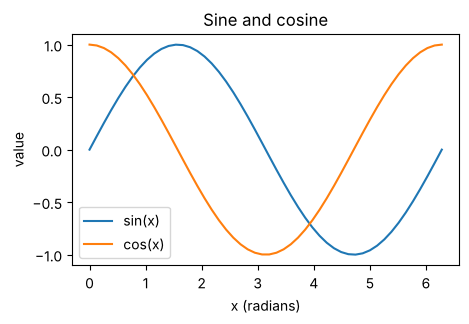

In [4]:
x = np.linspace(0, 2 * np.pi, 50)

plt.figure(figsize=(5, 3))
plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.cos(x), label="cos(x)")
plt.title("Sine and cosine")
plt.xlabel("x (radians)")
plt.ylabel("value")
plt.legend()
plt.show()

## 4. Two styles: `plt.` and `fig, ax`

So far we used the quick style, where `plt` secretly keeps track of "the current figure". It is fine for one plot.

For anything bigger, use the **object-oriented style**:

* `fig, ax = plt.subplots()` creates a figure (`fig`, the whole picture) and axes (`ax`, one plot inside it)
* you then call methods on `ax`: `ax.plot`, `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`, `ax.legend`

It is clearer, and it does not depend on hidden state. We use it from here on.

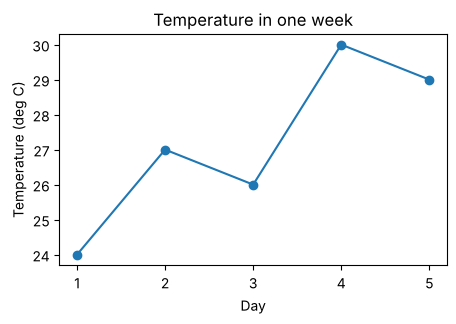

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(days, temp, marker="o")
ax.set_title("Temperature in one week")
ax.set_xlabel("Day")
ax.set_ylabel("Temperature (deg C)")
ax.set_xticks(days)         # show whole days only
plt.show()

## 5. Scatter plot

A scatter plot draws one dot per pair `(x, y)`, with no line. Use it to see whether two quantities are related.

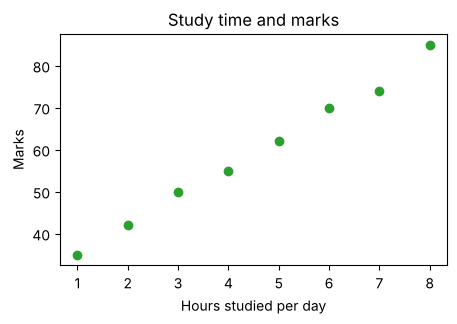

In [6]:
hours = [1, 2, 3, 4, 5, 6, 7, 8]
marks = [35, 42, 50, 55, 62, 70, 74, 85]

fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(hours, marks, color="tab:green")
ax.set_title("Study time and marks")
ax.set_xlabel("Hours studied per day")
ax.set_ylabel("Marks")
plt.show()

## 6. Bar chart

`ax.bar(names, heights)` compares values across categories.

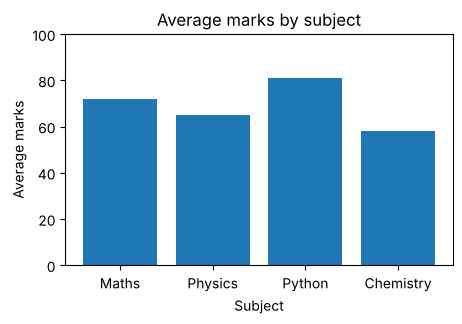

In [7]:
subjects = ["Maths", "Physics", "Python", "Chemistry"]
avg_marks = [72, 65, 81, 58]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(subjects, avg_marks, color="tab:blue")
ax.set_title("Average marks by subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Average marks")
ax.set_ylim(0, 100)
plt.show()

For long names use `ax.barh` (horizontal bars).

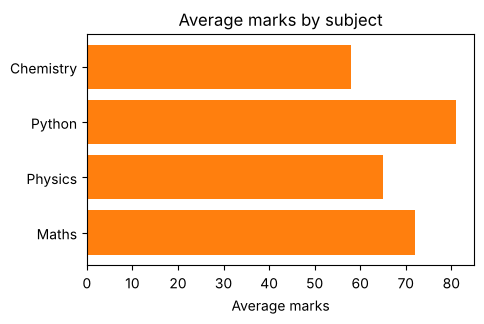

In [8]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.barh(subjects, avg_marks, color="tab:orange")
ax.set_title("Average marks by subject")
ax.set_xlabel("Average marks")
plt.show()

## 7. Histogram

A **histogram** shows how values are spread. It cuts the number line into **bins** and counts how many values fall in each. We use a fixed random seed so everyone gets the same data.

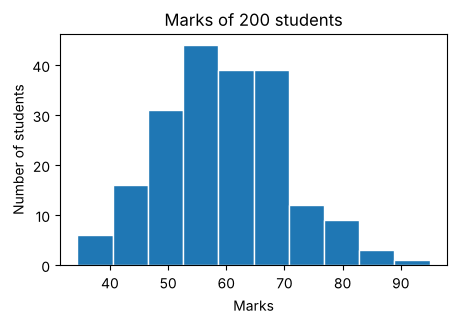

mean: 59.6


In [9]:
rng = np.random.default_rng(seed=42)
exam = rng.normal(loc=60, scale=12, size=200).clip(0, 100)

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(exam, bins=10, edgecolor="white")
ax.set_title("Marks of 200 students")
ax.set_xlabel("Marks")
ax.set_ylabel("Number of students")
plt.show()
print("mean:", round(exam.mean(), 1))

Try `bins=5` and `bins=30`. Too few bins hide the shape. Too many make it jumpy.

## 8. Several plots in one figure

`plt.subplots(rows, cols)` gives an array of axes. Use `figsize` for the total size and `fig.tight_layout()` to stop the labels overlapping.

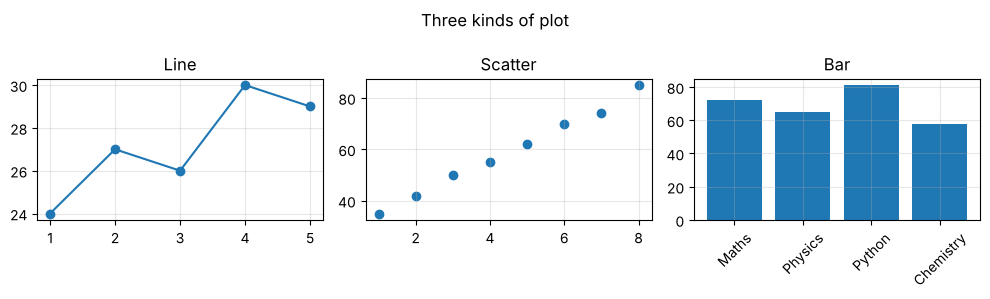

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

axes[0].plot(days, temp, marker="o")
axes[0].set_title("Line")

axes[1].scatter(hours, marks)
axes[1].set_title("Scatter")

axes[2].bar(subjects, avg_marks)
axes[2].set_title("Bar")
axes[2].tick_params(axis="x", rotation=45)     # turn long labels

for a in axes:
    a.grid(True, alpha=0.3)

fig.suptitle("Three kinds of plot")
fig.tight_layout()
plt.show()

(2, 2)


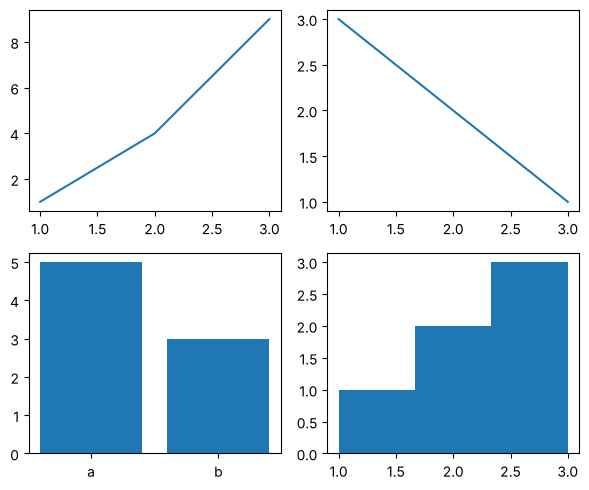

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(6, 5))      # axes is a 2 x 2 array
print(axes.shape)
axes[0, 0].plot([1, 2, 3], [1, 4, 9])
axes[0, 1].plot([1, 2, 3], [3, 2, 1])
axes[1, 0].bar(["a", "b"], [5, 3])
axes[1, 1].hist([1, 2, 2, 3, 3, 3], bins=3)
fig.tight_layout()
plt.show()

## 9. Saving a figure

`fig.savefig(path)` writes the figure to a file. The file type comes from the extension (`.png`, `.pdf`, `.svg`).
Use `dpi` for the sharpness of a PNG. We save into a temporary folder here, which is deleted afterwards.

file exists: True | size > 0: True


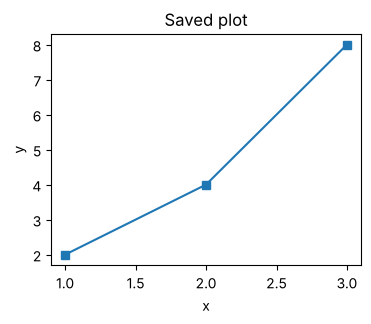

In [12]:
import os, tempfile

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot([1, 2, 3], [2, 4, 8], marker="s")
ax.set_title("Saved plot")
ax.set_xlabel("x")
ax.set_ylabel("y")

with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "plot.png")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("file exists:", os.path.exists(path), "| size > 0:", os.path.getsize(path) > 0)
plt.show()

Save **before** `plt.show()` in a script. In a plain script `show()` may close the figure, and you would save an empty one.

## 10. Edge cases

### 10.1 `plt.show()` in a script and in a notebook
In Jupyter, the figure appears automatically at the end of the cell, so `plt.show()` is optional (but good habit).
In a normal `.py` script run from the terminal, **nothing appears unless you call `plt.show()`**. It opens a window and waits until you close it.

Another point: `plt.show()` hides the line of text that a cell would print. Without it, the last expression of a cell is printed, such as `[<matplotlib.lines.Line2D at 0x...>]`. Ending a cell with `;` also hides it.

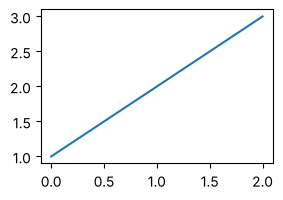

In [13]:
fig, ax = plt.subplots(figsize=(3, 2))
ax.plot([1, 2, 3]);       # the semicolon hides the returned object

### 10.2 x and y must have the same length
Different lengths give a `ValueError`. This usually means one list was filtered or built differently from the other.

In [14]:
fig, ax = plt.subplots(figsize=(3, 2))
try:
    ax.plot([1, 2, 3, 4], [10, 20, 30])
except ValueError as e:
    print("ValueError:", e)
plt.close(fig)       # throw this figure away

ValueError: x and y must have same first dimension, but have shapes (4,) and (3,)


### 10.3 State leaking between cells
`plt.plot` draws on "the current figure". If you do not start a new figure, a later cell can add lines to an old plot, or you can get an unexpected mix. Using `fig, ax = plt.subplots()` in every cell makes each plot independent.

Here we show what the hidden state is: `plt.gcf()` means "get current figure". A new `subplots` call makes a new current figure.

True
1 2


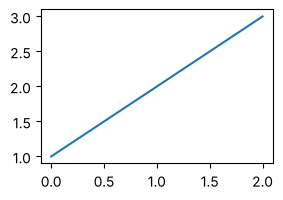

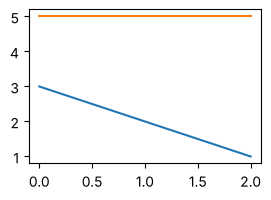

In [15]:
fig1, ax1 = plt.subplots(figsize=(3, 2))
ax1.plot([1, 2, 3])
fig2, ax2 = plt.subplots(figsize=(3, 2))
ax2.plot([3, 2, 1])

print(plt.gcf() is fig2)         # the newest figure is "current"
plt.plot([5, 5, 5])              # quick style draws on the CURRENT axes, which is ax2
print(len(ax1.lines), len(ax2.lines))    # ax1 has 1 line, ax2 got an extra line
plt.show()

With `ax1.plot(...)` and `ax2.plot(...)` you always say exactly where each line goes. Also, close figures you no longer need: `plt.close(fig)`. Many open figures use memory, and Matplotlib warns after 20.

In [16]:
plt.close("all")
print(plt.get_fignums())     # no figures left open

[]


### 10.4 Log scale and zeros
A log scale is useful when values span many powers of ten. But `log(0)` is not defined, and negative numbers have no log. Matplotlib cannot draw those points: they are dropped (and a warning may appear).

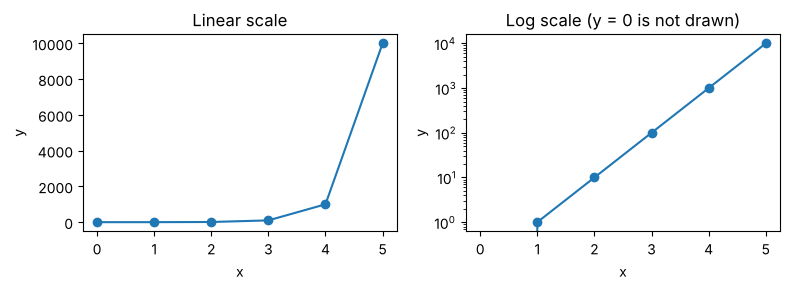

In [17]:
x = [0, 1, 2, 3, 4, 5]
y = [0, 1, 10, 100, 1000, 10000]

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(x, y, marker="o")
axes[0].set_title("Linear scale")

axes[1].plot(x, y, marker="o")
axes[1].set_yscale("log")
axes[1].set_title("Log scale (y = 0 is not drawn)")

for a in axes:
    a.set_xlabel("x")
    a.set_ylabel("y")
fig.tight_layout()
plt.show()

To keep a zero, use `ax.set_yscale("symlog")` (log scale that is linear near zero), or add a small number, or plot `np.log10(y + 1)` and say so in the label.

### 10.5 Category order on a bar chart
Strings are placed on the axis **in the order you give them**, not alphabetical order. If your data comes in a random order, the chart will look messy. Sort it yourself.

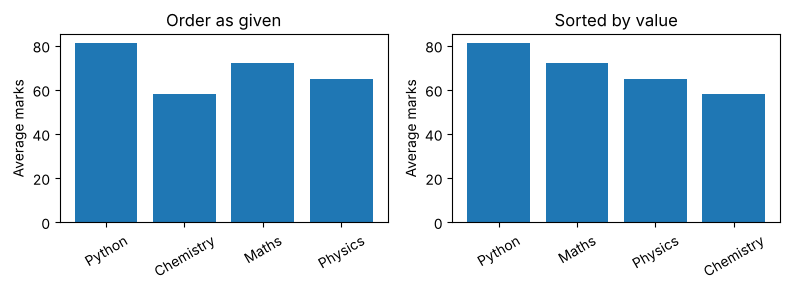

In [18]:
data = {"Python": 81, "Chemistry": 58, "Maths": 72, "Physics": 65}

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].bar(list(data.keys()), list(data.values()))
axes[0].set_title("Order as given")

ordered = sorted(data.items(), key=lambda kv: kv[1], reverse=True)
axes[1].bar([k for k, v in ordered], [v for k, v in ordered])
axes[1].set_title("Sorted by value")

for a in axes:
    a.set_ylabel("Average marks")
    a.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

Also beware: numbers written as **strings** (for example `"10"`, `"9"`, `"100"`) are treated as categories in the order given, not as numbers on a number line. Convert them to numbers first.

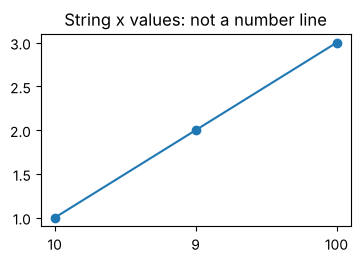

In [19]:
fig, ax = plt.subplots(figsize=(4, 2.5))
ax.plot(["10", "9", "100"], [1, 2, 3], marker="o")    # x are strings
ax.set_title("String x values: not a number line")
plt.show()

## 11. Quick summary

| Task | Code |
|---|---|
| Start | `fig, ax = plt.subplots(figsize=(5, 3))` |
| Line | `ax.plot(x, y, marker="o", label="name")` |
| Scatter | `ax.scatter(x, y)` |
| Bar | `ax.bar(names, heights)`, `ax.barh(...)` |
| Histogram | `ax.hist(values, bins=10)` |
| Text | `ax.set_title(...)`, `ax.set_xlabel(...)`, `ax.set_ylabel(...)` |
| Legend, grid | `ax.legend()`, `ax.grid(True)` |
| Several plots | `fig, axes = plt.subplots(rows, cols)`, then `fig.tight_layout()` |
| Save | `fig.savefig("file.png", dpi=150)` |
| Show / free | `plt.show()`, `plt.close(fig)` |
| Traps | no `show()` in scripts, equal lengths, log of 0, category order, string numbers |

## 12. Exercises

### Exercise 1

Plot the squares of the numbers 0 to 10 as a line with circle markers. Add a title and labels for both axes.

In [20]:
# Write your answer here

<details>
<summary><b>Show solution 1</b></summary>

```python
n = list(range(0, 11))
sq = [i * i for i in n]
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(n, sq, marker="o")
ax.set_title("Squares of 0 to 10")
ax.set_xlabel("n")
ax.set_ylabel("n squared")
plt.show()
```

</details>

### Exercise 2

Plot `y = x**2` and `y = x**3` for x from -2 to 2 (use `np.linspace` with 100 points) on the same axes. Give each line a label and show a legend.

In [21]:
# Write your answer here

<details>
<summary><b>Show solution 2</b></summary>

```python
x = np.linspace(-2, 2, 100)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, x ** 2, label="x squared")
ax.plot(x, x ** 3, label="x cubed")
ax.set_title("Two power functions")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(True)
plt.show()
```

</details>

### Exercise 3

Make a bar chart of the number of students per branch: `CSE = 40, ECE = 30, ME = 25, CE = 15`. Order the bars from the tallest to the shortest. Label the axes.

In [22]:
# Write your answer here

<details>
<summary><b>Show solution 3</b></summary>

The data is already in descending order, but sorting makes the code correct for any input order.

```python
branches = {"CSE": 40, "ECE": 30, "ME": 25, "CE": 15}
ordered = sorted(branches.items(), key=lambda kv: kv[1], reverse=True)
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar([k for k, v in ordered], [v for k, v in ordered], color="tab:purple")
ax.set_title("Students per branch")
ax.set_xlabel("Branch")
ax.set_ylabel("Number of students")
plt.show()
```

</details>

### Exercise 4

Use `rng = np.random.default_rng(1)` and `rng.integers(1, 7, size=300)` to simulate 300 rolls of a die. Draw a histogram with one bar per face, and print how many sixes were rolled.

*Hint:* use `bins=np.arange(0.5, 7.5, 1)` so each face sits in the middle of a bar.

In [23]:
# Write your answer here

<details>
<summary><b>Show solution 4</b></summary>

```python
rng = np.random.default_rng(1)
rolls = rng.integers(1, 7, size=300)
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(rolls, bins=np.arange(0.5, 7.5, 1), edgecolor="white")
ax.set_title("300 die rolls")
ax.set_xlabel("Face")
ax.set_ylabel("Count")
plt.show()
print("sixes:", (rolls == 6).sum())
```

</details>

### Exercise 5

Create a figure with two plots side by side. Left: a scatter plot of `x = [1, 2, 3, 4, 5]` against `y = [2, 4, 5, 4, 6]`. Right: a line plot of the same data. Give each a title and use `fig.tight_layout()`.

In [24]:
# Write your answer here

<details>
<summary><b>Show solution 5</b></summary>

`plt.subplots(1, 2)` returns two axes, which we can unpack into two names.

```python
x = [1, 2, 3, 4, 5]
y = [2, 4, 5, 4, 6]
fig, (left, right) = plt.subplots(1, 2, figsize=(8, 3))
left.scatter(x, y)
left.set_title("Scatter")
right.plot(x, y, marker="o")
right.set_title("Line")
for a in (left, right):
    a.set_xlabel("x")
    a.set_ylabel("y")
fig.tight_layout()
plt.show()
```

</details>

### Exercise 6

Save the figure from a small plot of your choice as `result.png` inside a `tempfile.TemporaryDirectory()`. Print whether the file exists, then check that it does not exist after the `with` block ends.

In [25]:
# Write your answer here

<details>
<summary><b>Show solution 6</b></summary>

The folder and its files are removed when the `with` block ends, so the second check prints `False`.

```python
import os, tempfile
fig, ax = plt.subplots(figsize=(3, 2))
ax.plot([1, 2, 3], [3, 1, 2])
ax.set_title("To save")
with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "result.png")
    fig.savefig(path)
    print(os.path.exists(path))
print(os.path.exists(path))
plt.show()
```

</details>

### Exercise 7

**Edge case.** The lists `years = [2020, 2021, 2022, 2023]` and `sales = [10, 100, 1000]` are different lengths. Wrap `ax.plot(years, sales)` in `try/except` and print the error. Then fix the problem by plotting only the years that have sales.

In [26]:
# Write your answer here

<details>
<summary><b>Show solution 7</b></summary>

The better fix is to find out why one list is shorter. Here we cut the longer list to match.

```python
years = [2020, 2021, 2022, 2023]
sales = [10, 100, 1000]
fig, ax = plt.subplots(figsize=(4, 3))
try:
    ax.plot(years, sales)
except ValueError as e:
    print("ValueError:", e)
ax.plot(years[:len(sales)], sales, marker="o")
ax.set_xticks(years[:len(sales)])
ax.set_title("Sales")
ax.set_xlabel("Year")
ax.set_ylabel("Sales")
plt.show()
```

</details>

## 13. Where to read more

* Software Carpentry, *Plotting*: https://swcarpentry.github.io/python-novice-gapminder/09-plotting.html
* Python Data Science Handbook, *Simple Line Plots*: https://jakevdp.github.io/PythonDataScienceHandbook/04.01-simple-line-plots.html
* Matplotlib documentation, *Quick start guide*: https://matplotlib.org/stable/users/explain/quick_start.html